In [1]:
!pip install kagglehub
import kagglehub

# Download latest version
path = kagglehub.dataset_download("blastchar/telco-customer-churn")

print("Path to dataset files:", path)


Using Colab cache for faster access to the 'telco-customer-churn' dataset.
Path to dataset files: /kaggle/input/telco-customer-churn


In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Define the directory path from kagglehub
data_dir = "/kaggle/input/telco-customer-churn"

# Find the CSV file inside that folder
files = os.listdir(data_dir)
csv_file = [f for f in files if f.endswith('.csv')][0]
file_path = os.path.join(data_dir, csv_file)

# Load the dataset
df = pd.read_csv(file_path)

# Display basic info and first few rows
print(f"Loaded file: {csv_file}")
print(f"Dataset Shape: {df.shape}")
print("\nFirst 5 rows:")
df.head()


Loaded file: WA_Fn-UseC_-Telco-Customer-Churn.csv
Dataset Shape: (7043, 21)

First 5 rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


--- Dataset Structural Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessB

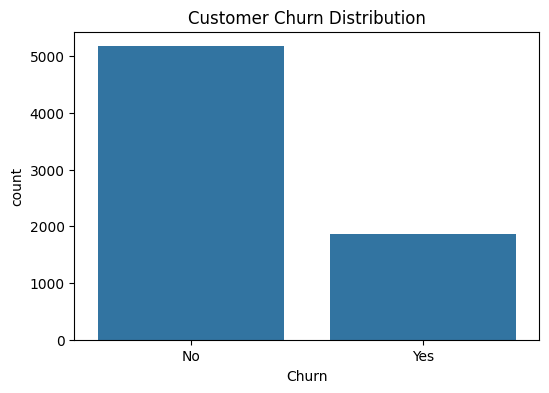


--- Cleaning Complete ---
Cleaned Features Shape X: (7032, 19)
Target Distribution y:
Churn
0    5163
1    1869
Name: count, dtype: int64


In [3]:
# 1. Check basic info and search for explicit missing values
print("--- Dataset Structural Info ---")
df.info()

print("\n--- Explicit Missing Values Count ---")
print(df.isnull().sum())

# 2. Plot target column distribution
plt.figure(figsize=(6,4))
sns.countplot(x='Churn', data=df)
plt.title('Customer Churn Distribution')
plt.show()

# 3. Clean and transform columns
df_clean = df.copy()

# Convert TotalCharges to numeric, transforming blank spaces into NaN
df_clean['TotalCharges'] = pd.to_numeric(df_clean['TotalCharges'], errors='coerce')

# Drop rows where TotalCharges is missing
df_clean = df_clean.dropna(subset=['TotalCharges'])

# Drop customerID since it has no predictive capabilities
df_clean = df_clean.drop(columns=['customerID'])

# Convert target label text to binary format (1 = Churn, 0 = No Churn)
df_clean['Churn'] = df_clean['Churn'].map({'Yes': 1, 'No': 0})

# Separate features from target
X = df_clean.drop(columns=['Churn'])
y = df_clean['Churn']

print("\n--- Cleaning Complete ---")
print(f"Cleaned Features Shape X: {X.shape}")
print(f"Target Distribution y:\n{y.value_counts()}")


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, recall_score, roc_auc_score, classification_report

# 1. Split the data into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 2. Identify numerical and categorical columns automatically
num_cols = X_train.select_dtypes(include=np.number).columns.tolist()
cat_cols = X_train.select_dtypes(exclude=np.number).columns.tolist()

# 3. Create individual pre-processing pipelines
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# 4. Combine pipelines into a single preprocessor
preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, num_cols),
    ('cat', categorical_pipeline, cat_cols)
])

# 5. Define full model execution pipelines
lr_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

rf_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42))
])

# 6. Train models and print metrics
for name, model in [("Logistic Regression", lr_model), ("Random Forest", rf_model)]:
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    print(f"\n================ {name} Results ================")
    print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.4f}")
    print(f"Recall Score:   {recall_score(y_test, y_pred):.4f}")
    print(f"ROC-AUC Score:  {roc_auc_score(y_test, y_proba):.4f}")
    print("\nDetailed Classification Report:")
    print(classification_report(y_test, y_pred))



================ Logistic Regression Results ================
Accuracy Score: 0.8038
Recall Score:   0.5722
ROC-AUC Score:  0.8359

Detailed Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1033
           1       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407


================ Random Forest Results ================
Accuracy Score: 0.7875
Recall Score:   0.4840
ROC-AUC Score:  0.8137

Detailed Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.90      0.86      1033
           1       0.63      0.48      0.55       374

    accuracy                           0.79      1407
   macro avg       0.73      0.69      0.70      1407
weighted avg       0.78      0.79      0.78      1407

